# Mini Project — Build a RAG System for Your Own Data
### IT7075: Applied AI for Cybersecurity · Retrieval-Augmented Generation

The first half of this notebook is the lecture pipeline with five pieces left for you to write, one per
step of the RAG recipe you saw in class:

| | Step | You write |
|---|---|---|
| **TODO 1** | chunk the documents | 3 lines |
| **TODO 2** | embed and store them in ChromaDB | 2 lines |
| **TODO 3** | retrieve the closest chunks | 3 lines |
| **TODO 4** | augment the prompt with what you retrieved | 2 lines |
| **TODO 5** | measure whether the answer was actually found | 4 lines |

Everything else is already written. Each TODO is marked like this, so you can find them by
searching for `###################`:

```
###################  TODO n — title  ###################
# what to do, and how
################
```

The five TODOs are practice on the course documents. After them, from Part 6 onward, no code is
provided: you build a RAG for data you create yourself, run your own experiments, and write it up in a
report and a video. Read `MiniProject_RAG.md` for the deliverables and the rubric.

> **Runs offline.** No API key needed. The generate step uses one if you have it, and otherwise
> prints an offline answer so the pipeline still works end to end.

## Part 1 — Chunk the documents  ·  **TODO 1**

The first few lines import what you need and load the embedding model — nothing to change there.
Then comes your first piece of code.

You cannot embed a whole document as one vector — one vector cannot represent ten topics. So you
cut each document into overlapping chunks, exactly as in Lecture 2. The **overlap** keeps a
sentence that lands on a boundary from being lost to both chunks.

> **Expected output:** `ssrf.txt -> 11 chunks`, `cybersecurity_kb.md -> 11 chunks`, **22 total**.

In [1]:
# If needed:  !pip install -q sentence-transformers chromadb pandas matplotlib openai
import json, os
import pandas as pd
import matplotlib.pyplot as plt

# Keep this notebook on the CPU. The model here is tiny (milliseconds either way),
# and this avoids the "CUDA error: no kernel image is available" failure -- or a very
# long hang while torch initialises -- on a machine whose PyTorch build does not match
# its GPU. This must run BEFORE anything imports torch.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

from sentence_transformers import SentenceTransformer
import chromadb

# ---- the documents that came with the course -----------------------------
def kb_path(name):
    """Look in the current folder first, then fall back to the course code folders."""
    if os.path.exists(name):
        return name
    p = "../../code/" + name
    if os.path.exists(p):
        return p
    return "../../../code/" + name

COURSE_KB = [kb_path("ssrf.txt"), kb_path("cybersecurity_kb.md")]

# the question set for those documents (Part 5) sits next to this notebook
GOLDSET_FILE = ("baseline_goldset.json" if os.path.exists("baseline_goldset.json")
                else "../baseline_goldset.json")

# ---- ONE embedding model, used for BOTH the chunks and the questions -----
embedder = SentenceTransformer("all-MiniLM-L6-v2")     # 384 numbers per text, runs locally

def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True).tolist()


###################  TODO 1 — cut a document into overlapping chunks  ###################
# WHAT: finish split_into_chunks() so it returns a list of text pieces.
#
# HOW (this is the Lecture 2 chunking cell):
#   * piece  = chunk_size characters of `text`, starting at `start`, with .strip()
#              applied so you don't keep leading/trailing whitespace
#   * append the piece to `pieces`, but ONLY if it is not an empty string
#   * move `start` forward by (chunk_size - overlap) -- NOT by chunk_size,
#     because the two chunks are supposed to share `overlap` characters
#
# WATCH OUT: if you move `start` forward by chunk_size you get no overlap at all;
#            if you forget to move it, the loop never ends.
################

def split_into_chunks(text, chunk_size=600, overlap=100):
    pieces = []
    start = 0
    while start < len(text):
        piece = text[start:start + chunk_size].strip()                                         # <<< 1 line
        if piece:                                                                              # <<< 1 line
            pieces.append(piece)
        start = start + chunk_size - overlap                                                   # <<< 1 line
    return pieces


# ---- given: apply it to both course documents ---------------------------
def load_and_chunk(files, chunk_size=600, overlap=100):
    """Read every file, chunk it, and remember which file each chunk came from."""
    chunks, sources = [], []
    for path in files:
        text = open(path, encoding="utf-8").read()
        pieces = split_into_chunks(text, chunk_size, overlap)
        chunks += pieces
        sources += [os.path.basename(path)] * len(pieces)
        print("  %-24s -> %2d chunks" % (os.path.basename(path), len(pieces)))
    return chunks, sources

chunks, sources = load_and_chunk(COURSE_KB)
print("  TOTAL:", len(chunks), "chunks")
print("\nFirst chunk starts:", chunks[0][:70])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

  ssrf.txt                 -> 11 chunks
  cybersecurity_kb.md      -> 11 chunks
  TOTAL: 22 chunks

First chunk starts: Server-Side Request Forgery Prevention Cheat Sheet
Introduction
The ob


## Part 2 — Embed and store in ChromaDB  ·  **TODO 2**

Now turn every chunk into a vector and put it in the vector database, as in Lecture 2. The
collection is created for you with `cosine` distance — Chroma's default is a different metric, and
every threshold in this notebook assumes cosine.

> **Expected output:** `Stored 22 chunks`.

In [2]:
client = chromadb.EphemeralClient()
_counter = [0]

def build_collection(chunks, sources):
    """Given: make a NEW empty collection using cosine distance, then fill it."""
    _counter[0] += 1                     # a fresh name each time, so re-running
    name = "kb_%d" % _counter[0]         # never mixes old chunks with new ones
    collection = client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})

    ###################  TODO 2 — put the chunks in the database  ###################
    # WHAT: give collection.add() the two arguments it is still missing.
    #
    # HOW (the Lecture 2 "operate ChromaDB" cell):
    #   * embeddings = the vectors for `chunks`. Use the embed() helper from
    #     Part 1 -- the SAME model must embed the chunks and, later, the question,
    #     or the distances mean nothing.
    #   * metadatas  = one small dict per chunk recording where it came from:
    #                  [{"source": s} for s in sources]
    #                  This is what lets an answer cite a file.
    ################

    collection.add(ids=["c%d" % i for i in range(len(chunks))],
                   documents=chunks,
                   embeddings=embed(chunks),                                # <<< 1 line
                   metadatas=[{"source": s} for s in sources])                                 # <<< 1 line
    return collection


collection = build_collection(chunks, sources)
print("Stored", collection.count(), "chunks")

Stored 22 chunks


## Part 3 — Retrieve  ·  **TODO 3**

Embed the question with the same model, ask the database for the `k` closest chunks, and throw
away anything farther than `max_distance`.

That last step is the one people skip, and it matters: without it the database **always** returns
`k` chunks no matter how irrelevant, so your bot will happily answer a question your documents
never covered. An empty result is a *good* result — Part 4 turns it into "I don't know".

> **Expected output:** 4 hits for the SSRF question with distances around 0.36–0.43, and
> **0 hits** for "What is the capital of France?".

In [3]:
###################  TODO 3 — find the closest chunks  ###################
# WHAT: finish retrieve() so it returns a list of hits, closest first.
#       Each hit is a dict: {"text": ..., "distance": ..., "source": ...}
#
# HOW (the Lecture 3 retrieve cell):
#   * query the collection with the EMBEDDED question and n_results=k:
#         results = collection.query(query_embeddings=embed([question]), n_results=k)
#   * Chroma wraps its answer in a list (one entry per question, and we asked one),
#     so the pieces you want are:
#         results["documents"][0]   results["distances"][0]   results["metadatas"][0]
#   * keep a hit only when its distance <= max_distance
#
# REMEMBER: cosine distance, so SMALL = similar. 0.0 is identical, 1.0 is unrelated.
################

def retrieve(collection, question, k=4, max_distance=0.75):
    results = collection.query(query_embeddings=embed([question]), n_results=k)           # <<< 1 line

    hits = []
    for doc, dist, meta in zip(results["documents"][0],
                               results["distances"][0],
                               results["metadatas"][0]):
        if dist <= max_distance:                                                           # <<< 1 line
            hits.append({"text": doc, "distance": dist, "source": meta["source"]})         # <<< 1 line
    return hits


# ---- given: try it on a question the documents answer, and one they don't
for q in ["Is SSRF limited to HTTP, or can other protocols be involved?",
          "What is the capital of France?"]:
    found = retrieve(collection, q)
    print("Q:", q)
    print("   hits:", len(found))
    for h in found:
        print("     distance %.3f  [%s]  %s..." % (h["distance"], h["source"],
                                                   h["text"][:60].replace("\n", " ")))
    print()

Q: Is SSRF limited to HTTP, or can other protocols be involved?
   hits: 4
     distance 0.356  [ssrf.txt]  ed, and if poorly handled, can perform specific injection at...
     distance 0.399  [ssrf.txt]  teract with the internal/external network or the machine its...
     distance 0.405  [ssrf.txt]  ed to perform an SSRF attack. Take a look at the XXE cheat s...
     distance 0.431  [ssrf.txt]  ill be based on the following information:  String containin...

Q: What is the capital of France?
   hits: 0



## Part 4 — Augment the prompt and generate  ·  **TODO 4**

Augmentation is just building a string: paste the retrieved chunks into the prompt and tell the
model to answer from them only. `generate()` and `ask()` are written for you.

> **Expected output:** the SSRF question comes back tagged `[RAG]`; the Log4Shell question comes
> back tagged `[LLM]` with no context — the honest refusal from Lecture 3.

In [4]:
SYSTEM = (
    "You are a cybersecurity assistant. Answer the question using ONLY the context below.\n"
    "Cite the source file for every claim, like [ssrf.txt]. If the answer is in the context, start "
    "your reply with [RAG]. If the context is empty or does not contain the answer, say you do not "
    "know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)

###################  TODO 4 — build the context block  ###################
# WHAT: finish build_context() so it turns a list of hits into ONE string.
#
# Format each hit like this, so the answer can be traced back to a file:
#
#     [1] (source: ssrf.txt)
#     <the chunk text>
#
#     [2] (source: cybersecurity_kb.md)
#     <the chunk text>
#
# HOW:
#   * loop over hits with  enumerate(hits, start=1)  so the numbering starts at 1
#   * build each block as  "[%d] (source: %s)\n%s" % (i, h["source"], h["text"])
#   * join the blocks with a BLANK LINE between them:  "\n\n".join(blocks)
#
# IMPORTANT: return "" when hits is empty. That empty string is what triggers the
#            [LLM] refusal path below -- do not return "no results" text instead.
################

def build_context(hits):
    if not hits:
        return ""
    blocks = []
    for i, h in enumerate(hits, start=1):
        blocks.append("[%d] (source: %s)\n%s" % (i, h["source"], h["text"]))                                                  # <<< 1 line
    return "\n\n".join(blocks)                                                              # <<< 1 line


# ---- given: generate an answer, then the whole pipeline in one function --
_USE_API = [True]      # set to False after one failure, so we don't retry a dead key

def generate(system, user):
    """Uses an LLM if one is available; otherwise quotes the context so this runs offline.

    The API call is guarded: if your key is missing, expired, or out of credit, the
    notebook prints one short note and keeps going in offline mode. Retrieval,
    scoring, and the whole tuning experiment do not need an LLM at all.
    """
    if os.getenv("OPENAI_API_KEY") and _USE_API[0]:
        try:
            from openai import OpenAI
            r = OpenAI().chat.completions.create(
                model="gpt-4o-mini", temperature=0,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
            return r.choices[0].message.content
        except Exception as e:
            _USE_API[0] = False
            print("   (LLM unavailable - %s. Switching to offline mode for the rest of the"
                  " notebook; nothing in this project needs an LLM.)" % type(e).__name__)

    context = system.split("# Context\n", 1)[-1]
    if context.strip() == "" or context.strip() == "(nothing found)":
        return "[LLM] I don't know -- the documents do not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context:\n" + context[:300]


def ask(collection, question, k=4, max_distance=0.75, show=True):
    """The complete RAG pipeline: retrieve -> augment -> generate."""
    hits = retrieve(collection, question, k, max_distance)
    context = build_context(hits)
    system = SYSTEM.format(context=context if context else "(nothing found)")
    answer = generate(system, question)
    if show:
        print("Q:", question)
        print("   grounded?", "YES, %d chunk(s)" % len(hits) if hits else "NO, nothing retrieved")
        print("   answer:", answer[:300].replace("\n", "\n           "), "\n")
    return {"hits": hits, "answer": answer}


_ = ask(collection, "What are the two basic cases in which SSRF can happen?")
_ = ask(collection, "What CVSS score did Log4Shell receive?")     # not in the documents

Q: What are the two basic cases in which SSRF can happen?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: ssrf.txt)
           ed to perform an SSRF attack. Take a look at the XXE cheat sheet to learn how to prevent exposure to XXE.
           Cases
           Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen:
           
            

Q: What CVSS score did Log4Shell receive?
   grounded? NO, nothing retrieved
   answer: [LLM] I don't know -- the documents do not cover this. (offline mode) 



## Part 5 — Measure it  ·  **TODO 5**

To say one setting is better than another you need a number. `baseline_goldset.json` has **8
questions** about the course documents: **6 the documents answer** (each with the exact `evidence`
wording that proves it) and **2 they do not**.

Two counts, and that is all:

- **found** — of the 6 answerable questions, how many retrieved a chunk containing the evidence?
- **refused** — of the 2 unanswerable ones, how many correctly retrieved *nothing*?

> **Expected output at the Lecture 3 settings (k=4, threshold 0.75): found 6/6, refused 2/2.**

In [5]:
GOLDSET = json.load(open(GOLDSET_FILE))["questions"]
print("Loaded", len(GOLDSET), "questions\n")

###################  TODO 5 — score one configuration  ###################
# WHAT: finish score() so it counts `found` and `refused`.
#
# For each question q in the gold set, retrieve() is already called for you.
# Then:
#   * if q["answerable"] is True:
#       - the question counts as FOUND when ANY retrieved hit contains ANY of the
#         phrases in q["evidence"]. Compare in lower case, because the documents
#         are not consistently capitalised:
#             phrase.lower() in hit["text"].lower()
#       - a small helper, found_evidence(hits, q["evidence"]), is started for you
#   * if q["answerable"] is False:
#       - it counts as REFUSED when len(hits) == 0 -- nothing was retrieved
#
# WHY only these two numbers: `found` tells you whether the right text reached the
# model, and `refused` tells you whether the bot keeps quiet when it should. A
# setting that improves one while wrecking the other is not an improvement.
################

def found_evidence(hits, evidence):
    for h in hits:
        for phrase in evidence:
            if phrase.lower() in h["text"].lower():                                       # <<< 1 line
                return True
    return False


def score(collection, goldset, k=4, max_distance=0.75):
    found, refused = 0, 0
    for q in goldset:
        hits = retrieve(collection, q["question"], k, max_distance)
        if q["answerable"]:
            if found_evidence(hits, q["evidence"]):                                       # <<< 1 line
                found += 1                                                                # <<< 1 line
        else:
            if len(hits) == 0:                                                            # <<< 1 line
                refused += 1
    return found, refused


n_answerable = sum(q["answerable"] for q in GOLDSET)
n_unanswerable = len(GOLDSET) - n_answerable

found, refused = score(collection, GOLDSET)
print("found   %d/%d answerable questions" % (found, n_answerable))
print("refused %d/%d unanswerable questions" % (refused, n_unanswerable))

Loaded 8 questions

found   6/6 answerable questions
refused 2/2 unanswerable questions


## Part 6: from here on, the code is yours

Everything above ran on the course documents, and it was practice: the same pipeline you saw in the
lectures, one piece at a time. The rest of this notebook is a RAG for your own data, and no code is
provided for it. Reuse anything you wrote in Parts 1 to 5, adapt code from the lecture notebooks, or
write something different. What matters is that it works on your data and that you can explain it.

Add cells below that do all of the following:

1. Load your documents from `my_kb/` and report how many documents and how many characters you have.
2. Load your questions from `goldset.json`, and check that every evidence phrase really appears in your
   documents exactly as written. If one does not, your own results will report a miss that is not real.
3. Chunk, embed, and store your documents.
4. Answer your questions and print the transcript, including at least one question your documents cannot
   answer, so that the refusal is visible.
5. Run your experiments. Change one setting at a time, such as chunk size, the number of chunks
   retrieved, or the distance threshold, score each configuration against your gold set, collect the
   results in a table, and save it as `results.csv`.
6. Draw at least one chart from your results and save it as a `.png`.

The cells below are empty on purpose. Add as many more as you need.

> When you are finished, run the whole notebook top to bottom and save it with the outputs showing,
> then commit it to your private GitHub repository along with `my_kb/`, `goldset.json`, `results.csv`,
> and your chart. See `MiniProject_RAG.md` section 7.1 for the folder structure.

In [6]:
###################  YOUR DATA — load and check  ###################
# Load your documents from my_kb/ and your questions from goldset.json.
# Report the document count and total characters, and check that every
# evidence phrase appears in your documents word-for-word.
################


from pathlib import Path
import json

# Load our original cybersecurity knowledge base.
my_documents = {}

for file in sorted(Path("my_kb").glob("*.md")):
    if file.name == "SOURCES.md":
        continue
    my_documents[file.name] = file.read_text(encoding="utf-8")

total_characters = sum(len(text) for text in my_documents.values())

print("Documents loaded:", len(my_documents))
print("Total characters:", total_characters)

for name, text in my_documents.items():
    print(f"  {name}: {len(text)} characters")

# Load our eight custom evaluation questions.
with open("goldset.json", encoding="utf-8") as file:
    my_goldset = json.load(file)["questions"]

print("\nQuestions loaded:", len(my_goldset))

# Check evidence directly against the original source files.
assert len(my_documents) == 5
assert len(my_goldset) == 8
assert sum(q["answerable"] for q in my_goldset) == 6

for q in my_goldset:
    if q["answerable"]:
        source_text = my_documents[q["source"]]
        for phrase in q["evidence"]:
            assert phrase in source_text, (
                f"Evidence missing for {q['qid']}: {phrase}"
            )

print("All evidence phrases verified!")


Documents loaded: 5
Total characters: 13718
  email_authentication.md: 2678 characters
  incident_response.md: 2751 characters
  malware_analysis.md: 2648 characters
  phishing_triage.md: 2883 characters
  security_awareness.md: 2758 characters

Questions loaded: 8
All evidence phrases verified!


### Build your RAG and ask your questions

In [7]:
###################  YOUR RAG — build and ask  ###################
# Chunk, embed, and store your documents, then answer your own questions.
# Print the transcript, including a question your documents cannot answer.
################


# Reuse our existing chunking and embedding functions
my_chunks = []
my_sources = []

for filename, text in my_documents.items():
    pieces = split_into_chunks(text, chunk_size=600, overlap=100)
    my_chunks.extend(pieces)
    my_sources.extend([filename] * len(pieces))

print("Custom chunks created:", len(my_chunks))

# Build a separate vector database for our cybersecurity documents
my_collection = build_collection(my_chunks, my_sources)

print("Custom chunks stored:", my_collection.count())

# Evaluate retrieval against our eight custom questions
my_found, my_refused = score(
    my_collection,
    my_goldset,
    k=4,
    max_distance=0.75
)

print(f"\nEvidence found: {my_found}/6")
print(f"Refusals held: {my_refused}/2")

# Demonstrate the complete RAG pipeline
print("\n=== CUSTOM RAG TRANSCRIPT ===")

for q in my_goldset:
    print(f"\nQuestion {q['qid']}:")
    ask(
        my_collection,
        q["question"],
        k=4,
        max_distance=0.75
    )


Custom chunks created: 30
Custom chunks stored: 30

Evidence found: 6/6
Refusals held: 1/2

=== CUSTOM RAG TRANSCRIPT ===

Question Q1:
Q: What details should an analyst record before classifying a reported phishing email?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: phishing_triage.md)
           # Fictional SOC Runbook: Phishing Email Triage
           
           ## Purpose and scope
           This runbook is an original educational simulation for a fictional small security operations center (SOC). It defines how analysts should handle empl 


Question Q2:
Q: Which email authentication policies or dispositions does DMARC commonly describe?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: email_authentication.md)
           g domain and whether verification passed, failed, or was unavailable. A failed signature can have benign explanations, such as cont

### Run your experiments and collect the results

In [8]:
###################  YOUR EXPERIMENTS  ###################
# Change one setting at a time, score each configuration against your gold
# set, collect the rows into a table, and save it as results.csv.
################


# Each experiment changes only one setting from the baseline.
experiments = [
    ("Baseline", 600, 4, 0.75),
    ("Small chunks", 300, 4, 0.75),
    ("Large chunks", 900, 4, 0.75),
    ("Fewer hits", 600, 2, 0.75),
    ("More hits", 600, 6, 0.75),
    ("Strict threshold", 600, 4, 0.50),
    ("Loose threshold", 600, 4, 0.90),
]

experiment_results = []
baseline_collection = None

for name, chunk_size, k, max_distance in experiments:

    # Split our five cybersecurity documents into chunks.
    test_chunks = []
    test_sources = []

    for filename, text in my_documents.items():
        pieces = split_into_chunks(
            text,
            chunk_size=chunk_size,
            overlap=100
        )

        test_chunks.extend(pieces)
        test_sources.extend([filename] * len(pieces))

    # Build a fresh ChromaDB collection for this experiment.
    test_collection = build_collection(test_chunks, test_sources)

    # Keep the EXACT baseline collection for failure analysis.
    if name == "Baseline":
        baseline_collection = test_collection

    # Score the six answerable and two unanswerable questions.
    found, refused = score(
        test_collection,
        my_goldset,
        k=k,
        max_distance=max_distance
    )

    # Record the actual experiment results.
    experiment_results.append({
        "configuration": name,
        "chunk_size": chunk_size,
        "overlap": 100,
        "k": k,
        "max_distance": max_distance,
        "found": found,
        "refused": refused
    })

# Store all seven configurations in a results table.
results_df = pd.DataFrame(experiment_results)

# Export the results to the required CSV file.
results_df.to_csv("results.csv", index=False)

print("=== RAG EXPERIMENT RESULTS ===")
print(results_df.to_string(index=False))

print("\nSaved results.csv")
print("Baseline collection:", baseline_collection.name)



=== RAG EXPERIMENT RESULTS ===
   configuration  chunk_size  overlap  k  max_distance  found  refused
        Baseline         600      100  4          0.75      6        1
    Small chunks         300      100  4          0.75      5        1
    Large chunks         900      100  4          0.75      6        1
      Fewer hits         600      100  2          0.75      5        1
       More hits         600      100  6          0.75      6        1
Strict threshold         600      100  4          0.50      6        1
 Loose threshold         600      100  4          0.90      6        1

Saved results.csv
Baseline collection: kb_3


### Chart your results

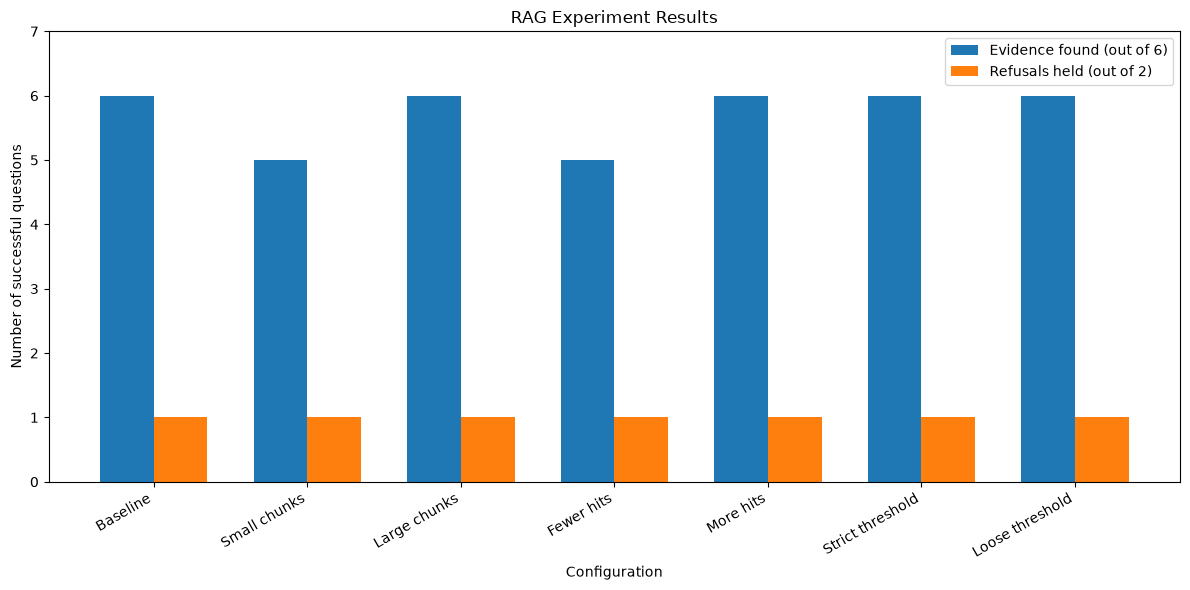

Saved figure.png


In [9]:
###################  YOUR CHART  ###################
# Draw at least one chart from your results and save it as a .png.
################


import matplotlib.pyplot as plt
import numpy as np

# Use the actual experimental results
labels = results_df["configuration"]
found = results_df["found"]
refused = results_df["refused"]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width / 2, found, width, label="Evidence found (out of 6)")
ax.bar(x + width / 2, refused, width, label="Refusals held (out of 2)")

ax.set_title("RAG Experiment Results")
ax.set_ylabel("Number of successful questions")
ax.set_xlabel("Configuration")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylim(0, 7)
ax.legend()

plt.tight_layout()
plt.savefig("figure.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure.png")


In [10]:

# ============================================================
# BASELINE FAILURE ANALYSIS
# ============================================================

print("=== BASELINE REFUSAL ANALYSIS ===")

# Verify that the experiment created a baseline collection.
assert baseline_collection is not None

# Examine only the two unanswerable questions.
for q in my_goldset:

    if not q["answerable"]:

        hits = retrieve(
            baseline_collection,
            q["question"],
            k=4,
            max_distance=0.75
        )

        print("\nQuestion:", q["question"])
        print("Retrieved hits:", len(hits))
        print("Correctly refused:", len(hits) == 0)

        # Display the misleading evidence when retrieval fails to refuse.
        for h in hits:
            print("\nSource:", h["source"])
            print("Cosine distance:", round(h["distance"], 4))
            print("Retrieved passage:")
            print(h["text"])

# Recalculate scores using the exact experiment baseline.
baseline_found, baseline_refused = score(
    baseline_collection,
    my_goldset,
    k=4,
    max_distance=0.75
)

print("\n=== BASELINE VERIFICATION ===")
print("Evidence found:", baseline_found, "/6")
print("Refusals held:", baseline_refused, "/2")

# Compare the diagnostic scores with the saved results.
expected = results_df.loc[
    results_df["configuration"] == "Baseline"
].iloc[0]

assert baseline_found == int(expected["found"]), (
    "Evidence score does not match the experiment."
)

assert baseline_refused == int(expected["refused"]), (
    "Refusal score does not match the experiment."
)

print("\nPASS: Failure analysis matches experiment results!")



=== BASELINE REFUSAL ANALYSIS ===

Question: What is the capital city of Iceland?
Retrieved hits: 0
Correctly refused: True

Question: What is the exact annual dollar budget for the fictional SOC security awareness program?
Retrieved hits: 4
Correctly refused: False

Source: security_awareness.md
Cosine distance: 0.4906
Retrieved passage:
# Fictional SOC Guide: Security Awareness and Reporting

## Program goals
This original educational guide describes a fictional company's awareness program. Its primary goal is to help employees recognize suspicious activity, report it quickly, and understand what happens after a report. Training should emphasize practical actions rather than fear or punishment. This document deliberately does not provide an annual training budget or a numeric spending target.

## Employee phishing reporting
Employees should report suspicious messages using the approved phishing-reporting button or security he

Source: phishing_triage.md
Cosine distance: 0.6021
Retrie

---

## What to write up

The tables and charts above are the evidence. The report and the video are where you explain them.
See `MiniProject_RAG.md` for the full requirements. In short:

- Explain the complete RAG system in your own words: chunking, embeddings, the vector store, retrieval,
  augmentation, and generation, and where each one appears in your notebook.
- Describe the data you created and the questions you wrote, and why you chose the question your
  documents cannot answer.
- Report what your experiments showed: which setting changed your numbers most, what you would use, and
  whether anything found more answers while refusing less.
- Pick one question your RAG got wrong, look at the chunk it retrieved instead, and explain the mistake.

Submit one PDF report with the link to your GitHub project folder and the link to your video on its first
page. The notebook, `my_kb/`, `goldset.json`, `results.csv`, and your chart live in the repository, which
is private, with your instructor and the TA added as collaborators. The notebook must be committed with
its outputs showing.